<a href="https://colab.research.google.com/github/hamidatbi/himalaya-glof-risk/blob/main/Hymalias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



 **PHASE 1**

In [2]:
!pip install geemap

In [3]:
import ee
import geemap
print("all imported")

all imported


In [5]:
ee.Authenticate()
ee.Initialize(project='himalayan-glacial-risk')
print("done")

done


In [ ]:
lake=ee.Geometry.Point([88.198, 27.913])
print('lake saved')

In [6]:
s2=ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
print("Saved")

Saved


In [ ]:
before= (s2
         .filterBounds(lake)
         .filterDate('2022-10-10', '2022-11-30')
         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',30)))

after= (s2
         .filterBounds(lake)
         .filterDate('2023-10-10', '2023-11-30')
         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',30)))

print('Before images:', before.size().getInfo())
print('After images:', after.size().getInfo())

In [ ]:
before_img = before.median()
after_img = after.median()
print('done')

In [ ]:
vis= {'bands': ['B4', 'B3', 'B2'],
      'min': 0,
      'max': 6000}

map=geemap.Map(center=[27.913, 88.198], zoom=14, basemap='Esri.WorldImagery')

map.addLayer(before_img, vis, 'In 2022')
map.addLayer(after_img, vis, 'In 2023')

map

In [7]:
admin_bounds=ee.FeatureCollection("FAO/GAUL/2025/level1")
study_area = admin_bounds.filter(
    ee.Filter.Or(
        ee.Filter.inList('GAUL0_NAME', ['Bhutan', 'Nepal']),
        ee.Filter.eq('GAUL1_NAME', 'Sikkim')
    )
)

study_area.size().getInfo()

28

to see the columns:  geemap.ee_to_df(admin_bounds.limit(5))

In [8]:
#geemap.ee_to_df(admin_bounds.limit(5))

import pandas as pd

india = admin_bounds.filter(ee.Filter.eq('GAUL0_NAME', 'India'))
df = geemap.ee_to_df(india)

#df.head()
df[df['GAUL1_NAME']=='Sikkim']

,CONTINENT,DISP_EN,FID,GAUL0_CODE,GAUL0_NAME,GAUL1_CODE,GAUL1_NAME,ISO3_CODE,MAP_CODE
24,Asia,"Sikkim, India",1325,240,India,2608,Sikkim,IND,IND


In [9]:
map=geemap.Map(center=[28, 86.5], zoom=6, basemap='Esri.WorldImagery')
map.addLayer(study_area, {}, 'Study area')

aoi=study_area.union()
map.addLayer(aoi, {'color': 'red'}, 'AOI')

map

Map(center=[28, 86.5], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

In [10]:
copernicus=ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1")
dem=copernicus.select('DEM')

dem_proj = dem.first().projection()

mosaic=dem.mosaic().setDefaultProjection(dem_proj)
dem_aoi=mosaic.clip(aoi.geometry())



vis= {'palette':['green', 'yellow', 'brown', 'white'],
      'min': 0,
      'max': 8000}

map=geemap.Map(center=[27.913, 88.198], zoom=7, basemap='Esri.WorldImagery')
map.addLayer(dem_aoi, vis, 'DEM of study area')

map

Map(center=[27.913, 88.198], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

In [11]:
high_elev=dem_aoi.gt(4000)  #elevations more than 4000m: 1yes and 0no
masked_hel=dem_aoi.updateMask(high_elev)

map.addLayer(masked_hel,vis,'Elevations above 4k meters')
map

Map(bottom=14036.0, center=[27.913, 88.198], controls=(WidgetControl(options=['position', 'transparent_bg'], p…

**PHASE 2**

In [12]:
s2_2025= (s2
         .filterBounds(aoi.geometry())
         .filterDate('2025-09-15', '2025-11-30')
         .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE',30)))

#print('Lakes 2025 images count:', s2_2025.size().getInfo())

final_s2_2025=s2_2025.median().clip(aoi.geometry())

vis= {'bands': ['B4', 'B3', 'B2'],
      'min': 0,
      'max': 3000}

map=geemap.Map(center=[28, 86.5], zoom=7, basemap='Esri.WorldImagery')
map.addLayer(final_s2_2025, vis, "Median satellite image of Sep-Nov 2025")

map


Map(center=[28, 86.5], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

In [13]:
s2_2025_high_elev=final_s2_2025.updateMask(high_elev)
vis_high_elev={'bands': ['B4', 'B3', 'B2'],
               'min': 0,
               'max': 10000}

map.addLayer(s2_2025_high_elev, vis_high_elev, "High elevation image of Sep-Nov 2025")
map


Map(bottom=14027.0, center=[28, 86.5], controls=(WidgetControl(options=['position', 'transparent_bg'], positio…

In [28]:
s2_2025_high_elev=final_s2_2025.updateMask(high_elev)
ndwi=s2_2025_high_elev.normalizedDifference(['B3', 'B8'])

ndwi_vis={'palette': ['white', 'blue'],
          'min': -1,
          'max': 1}

map.addLayer(ndwi, ndwi_vis, "NDWI 2025")
map

Map(bottom=14027.0, center=[28, 86.5], controls=(WidgetControl(options=['position', 'transparent_bg'], positio…

In [15]:
ndsi=s2_2025_high_elev.normalizedDifference(['B3', 'B11'])

slope_n= ee.Terrain.slope(dem_aoi)
slope_high_elev=slope_n.updateMask(high_elev)
dem_high_elev=dem_aoi.updateMask(high_elev)

ndwi=ndwi.rename('NDWI')
ndsi=ndsi.rename('NDSI')

features=s2_2025_high_elev.addBands(ndwi).addBands(ndsi).addBands(slope_high_elev).addBands(dem_high_elev)

features.bandNames().getInfo()


['B1',
 'B2',
 'B3',
 'B4',
 'B5',
 'B6',
 'B7',
 'B8',
 'B8A',
 'B9',
 'B11',
 'B12',
 'AOT',
 'WVP',
 'SCL',
 'TCI_R',
 'TCI_G',
 'TCI_B',
 'MSK_CLDPRB',
 'MSK_SNWPRB',
 'QA10',
 'QA20',
 'QA60',
 'MSK_CLASSI_OPAQUE',
 'MSK_CLASSI_CIRRUS',
 'MSK_CLASSI_SNOW_ICE',
 'NDWI',
 'NDSI',
 'slope',
 'DEM']

In [16]:
final_features=features.select(['B2','B3','B4','B8','B11','B12','NDWI','NDSI','slope','DEM'])
final_features.bandNames().getInfo()


['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDWI', 'NDSI', 'slope', 'DEM']

In [ ]:
train_map=geemap.Map(center=[28, 86.5], zoom=7, basemap='Esri.WorldImagery')

train_map.addLayer(s2_2025_high_elev, vis_high_elev, "High elevations")
train_map.addLayer(ndwi, ndwi_vis, "NDWI")

train_map

In [ ]:
shadow_pts = train_map.user_rois

In [ ]:
lakes_pts = lakes_pts.map(lambda f: f.set('class', 0))
snow_pts = snow_pts.map(lambda f: f.set('class', 1))
rock_pts = rock_pts.map(lambda f: f.set('class', 2))
shadow_pts = shadow_pts.map(lambda f: f.set('class', 3))

training_pts = lakes_pts.merge(snow_pts).merge(rock_pts).merge(shadow_pts)



In [ ]:
print(training_pts.size().getInfo())

In [ ]:
task = ee.batch.Export.table.toAsset(
    collection=training_pts,
    description='training_points_2025',
    assetId='projects/himalayan-glacial-risk/assets/training_points_2025'
)
task.start()


In [ ]:
task.status()

In [17]:
training_pts = ee.FeatureCollection('projects/himalayan-glacial-risk/assets/training_points_2025')
training_pts.size().getInfo()

208

In [18]:
samples=final_features.sampleRegions(training_pts, ['class'], 10 )
print(samples.first().getInfo())
print(samples.size().getInfo())

{'type': 'Feature', 'geometry': None, 'id': '00000000000000000000_0', 'properties': {'B11': 46, 'B12': 52, 'B2': 1528, 'B3': 1950, 'B4': 1697, 'B8': 564, 'DEM': 4507.5, 'NDSI': 0.9539077877998352, 'NDWI': 0.5513126254081726, 'class': 0, 'slope': 0}}
208


In [19]:
print(training_pts.aggregate_histogram('class').getInfo())
print(samples.aggregate_histogram('class').getInfo())

{'0': 58, '1': 50, '2': 65, '3': 35}
{'0': 58, '1': 50, '2': 65, '3': 35}


In [20]:
df=geemap.ee_to_gdf(samples)
df.head()
#print(df.size())

,geometry,B11,B12,B2,B3,B4,B8,DEM,NDSI,NDWI,class,slope
0,None,46.0,52.0,1528.0,1950.0,1697.0,564.0,4507.500000,0.953908,0.551313,0,0.000000
1,None,36.0,47.0,1342.0,1749.0,1561.0,490.0,4544.146484,0.959664,0.562305,0,13.774552
2,None,44.5,47.5,1426.5,1888.0,1584.5,387.5,5299.500000,0.953946,0.659415,0,0.000000
3,None,46.0,50.5,1386.0,1864.0,1578.0,385.0,5299.500000,0.951832,0.657626,0,0.000000
4,None,33.5,42.0,0.0,0.0,0.0,0.0,5094.510742,-1.000000,0.000000,0,0.338581


In [21]:
features_var=['B11','B12','B2','B3','B4','B8','DEM','NDSI','NDWI','slope',]
X=df[features_var]
y=df['class']

print(X.head())
print(y)

    B11   B12      B2      B3      B4     B8          DEM      NDSI      NDWI  \
0  46.0  52.0  1528.0  1950.0  1697.0  564.0  4507.500000  0.953908  0.551313   
1  36.0  47.0  1342.0  1749.0  1561.0  490.0  4544.146484  0.959664  0.562305   
2  44.5  47.5  1426.5  1888.0  1584.5  387.5  5299.500000  0.953946  0.659415   
3  46.0  50.5  1386.0  1864.0  1578.0  385.0  5299.500000  0.951832  0.657626   
4  33.5  42.0     0.0     0.0     0.0    0.0  5094.510742 -1.000000  0.000000   

       slope  
0   0.000000  
1  13.774552  
2   0.000000  
3   0.000000  
4   0.338581  
0      0
1      0
2      0
3      0
4      0
      ..
203    3
204    3
205    3
206    3
207    3
Name: class, Length: 208, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

In [23]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape)
print(X_test.shape)

(145, 10)
(63, 10)


In [24]:
clf=RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
print('model trained')

model trained


In [25]:
y_pred=clf.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.9682539682539683
[[17  0  0  0]
 [ 0 15  0  0]
 [ 0  0 19  1]
 [ 0  0  1 10]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        17
           1       1.00      1.00      1.00        15
           2       0.95      0.95      0.95        20
           3       0.91      0.91      0.91        11

    accuracy                           0.97        63
   macro avg       0.96      0.96      0.96        63
weighted avg       0.97      0.97      0.97        63



<Axes: title={'center': 'Feature importance'}>

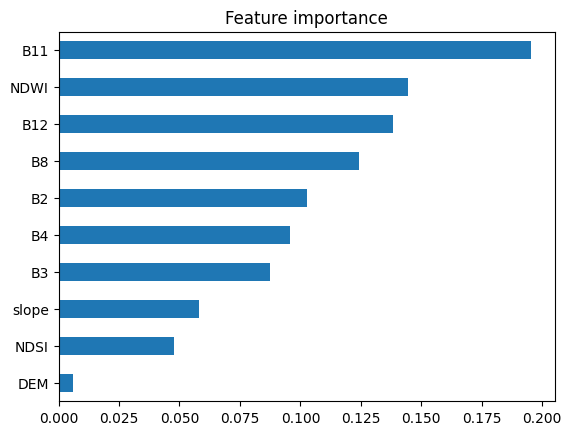

In [27]:
import pandas as pd

importance = pd.Series(clf.feature_importances_, index=features_var)
importance.sort_values().plot(kind='barh', title='Feature importance')

In [32]:
from geemap import ml

trees=ml.rf_to_strings(clf, features_var)
ee_classifier=ml.strings_to_classifier(trees)

classified=final_features.select(features_var).classify(ee_classifier)

class_vis={'min': 0,
           'max': 3,
           'palette':['0000FF', 'FFFFFF', '8B5A2B', '000000']}

map.addLayer(classified, class_vis, 'Classified image')
map

Map(bottom=14064575.602986136, center=[27.92992827007534, 90.71171842099861], controls=(WidgetControl(options=…